<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

# Synthetic Financial Time Series

**GAN-based Generation of Realistic Return Data (PyTorch)**

&copy; Dr. Yves J. Hilpisch

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>

## Imports & Settings

In [4]:
import os
import sys
import numpy as np
import pandas as pd
from pylab import plt, mpl

In [5]:
import torch
from torch import nn

In [6]:
sys.path.insert(0, os.path.abspath('..'))
from synthts.data import load_eod, compute_log_returns, ReturnScaler
from synthts.models import Generator, Discriminator, GAN
from synthts.train import train_gan, generate_samples
from synthts.evaluate import (ks_test, ks_test_batch, pass_rate,
    describe_comparison, mse_sorted,
    plot_real_vs_synth, plot_histograms, plot_sorted,
    plot_cumulative, plot_pvalue_histogram)

In [7]:
plt.style.use('seaborn-v0_8')
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['font.family'] = 'serif'

## Simple Example — Learning a Cubic Function

In [8]:
x = np.linspace(-2, 2, 500)
y = x ** 3

In [9]:
scaler = ReturnScaler()
y_ = scaler.fit_transform(y)

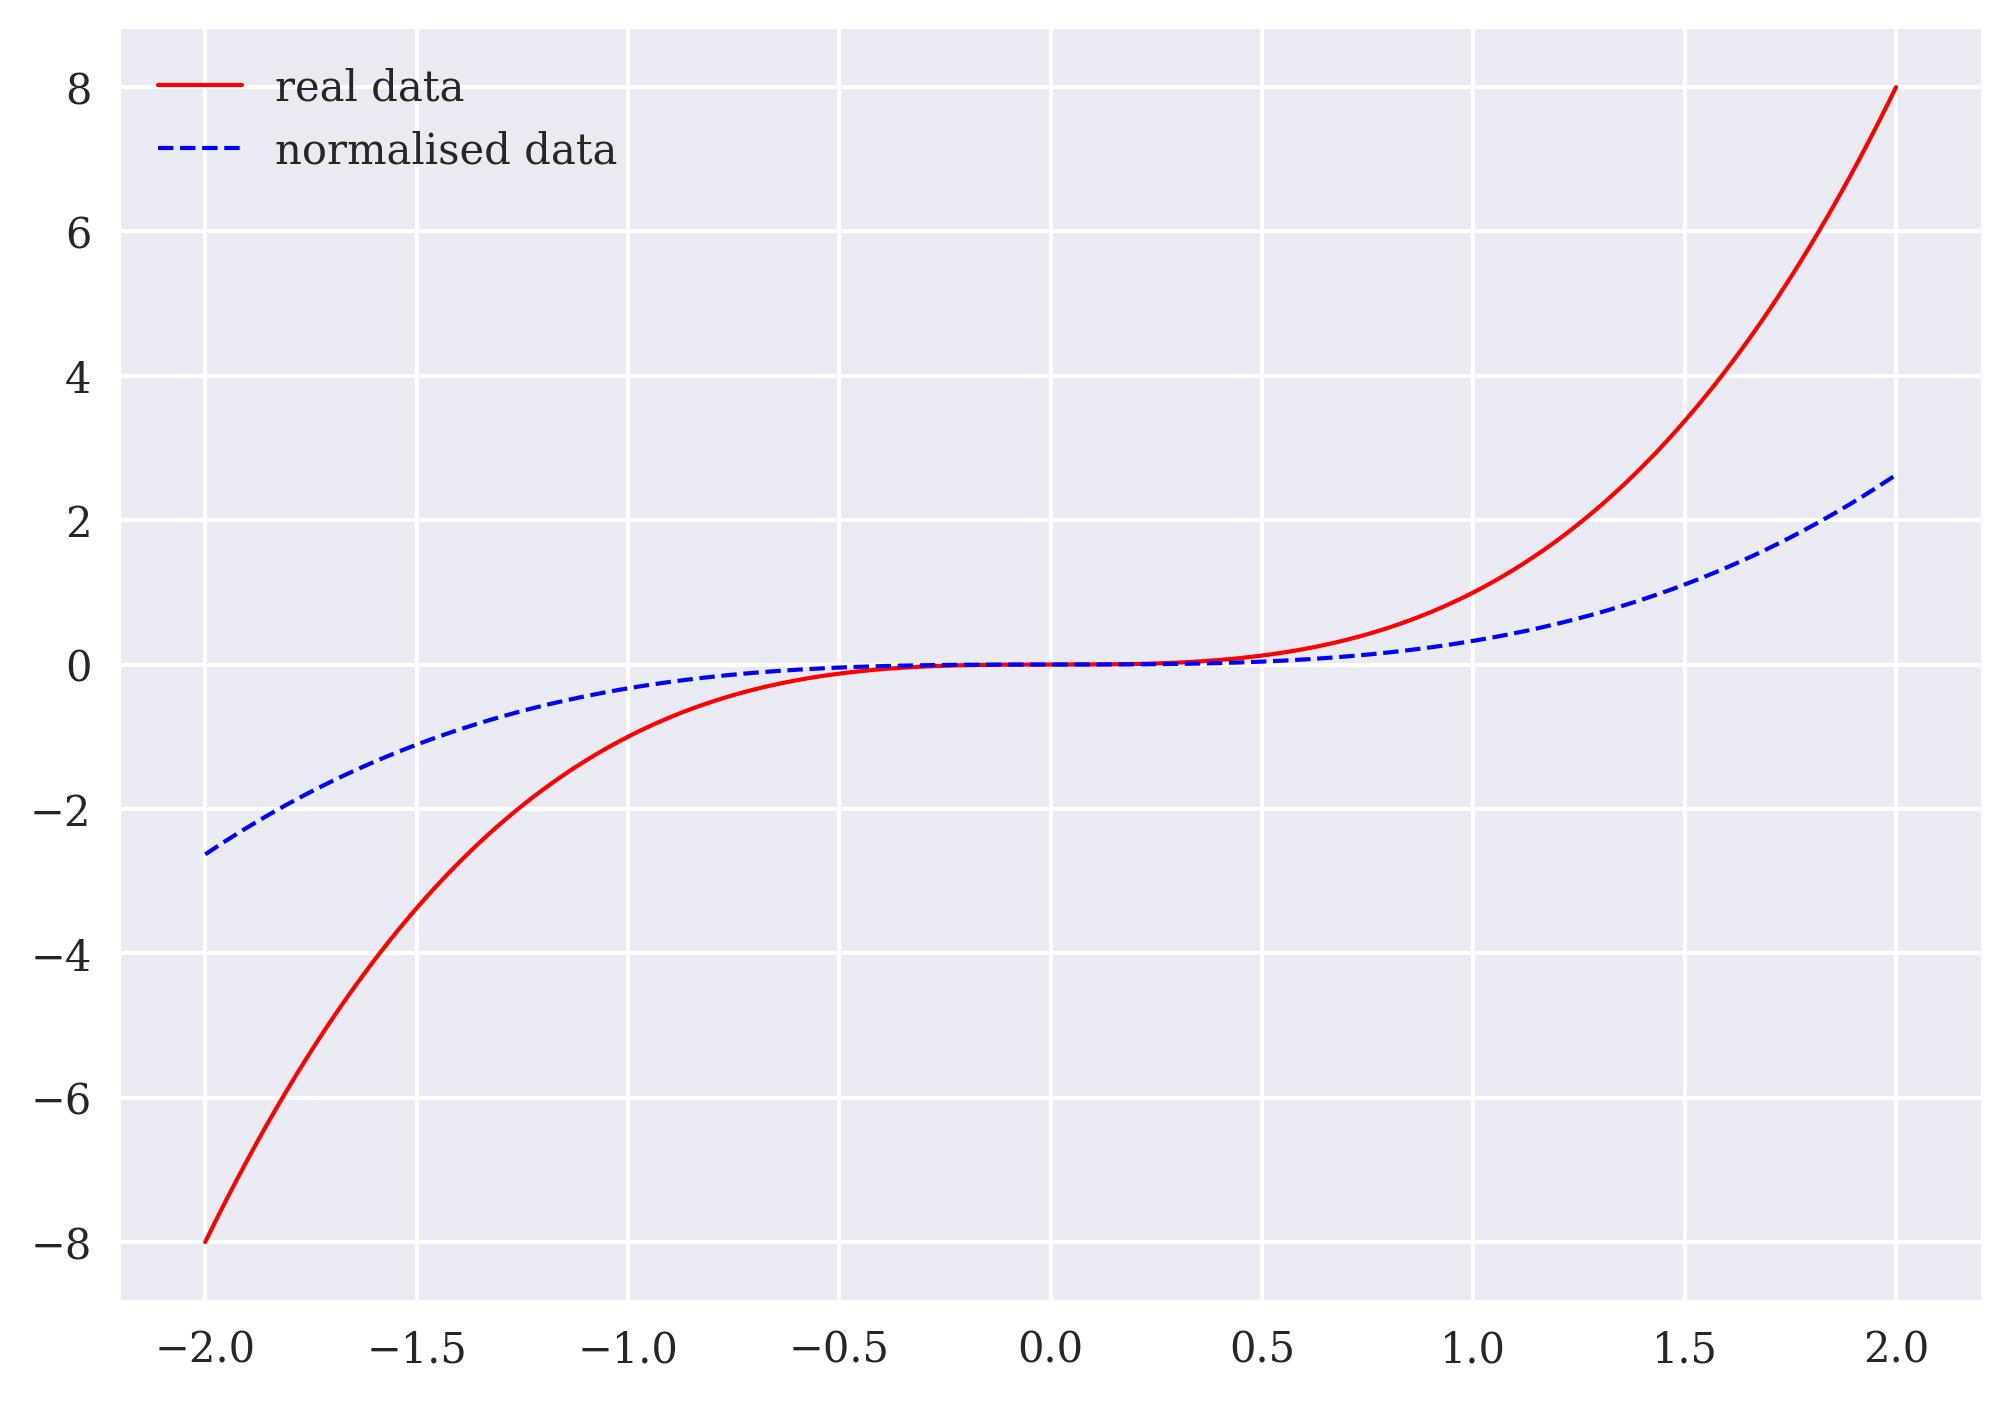

In [10]:
plt.plot(x, y, 'r', lw=1.0, label='real data')
plt.plot(x, y_, 'b--', lw=1.0, label='normalised data')
plt.legend();

### Model Training

In [11]:
generator = Generator(latent_dim=1, hidden_units=32, output_dim=1)
discriminator = Discriminator(input_dim=1, hidden_units=32)

In [17]:
%%time
history = train_gan(
    generator, discriminator, y_.reshape(-1, 1),
    epochs=15001, batch_size=32,
    lr_d=0.001, lr_g=0.0001, seed=100
)

Epoch     0 | D_real: 0.6792 D_fake: 0.6841 G: 0.7034
Epoch  1000 | D_real: 0.7051 D_fake: 0.6955 G: 0.7179
Epoch  2000 | D_real: 0.6888 D_fake: 0.6804 G: 0.6934
Epoch  3000 | D_real: 0.6888 D_fake: 0.7023 G: 0.6830
Epoch  4000 | D_real: 0.6912 D_fake: 0.6878 G: 0.7007
Epoch  5000 | D_real: 0.6787 D_fake: 0.6982 G: 0.6925
Epoch  6000 | D_real: 0.6967 D_fake: 0.6891 G: 0.6923
Epoch  7000 | D_real: 0.6909 D_fake: 0.6945 G: 0.6926
Epoch  8000 | D_real: 0.6945 D_fake: 0.6927 G: 0.7053
Epoch  9000 | D_real: 0.7077 D_fake: 0.6909 G: 0.6922
Epoch 10000 | D_real: 0.6953 D_fake: 0.6926 G: 0.6957
Epoch 11000 | D_real: 0.6912 D_fake: 0.6955 G: 0.6923
Epoch 12000 | D_real: 0.6923 D_fake: 0.6943 G: 0.6942
Epoch 13000 | D_real: 0.6965 D_fake: 0.6918 G: 0.6944
Epoch 14000 | D_real: 0.6969 D_fake: 0.6884 G: 0.6995
Epoch 15000 | D_real: 0.6890 D_fake: 0.6975 G: 0.6879
CPU times: user 5.91 s, sys: 12.9 ms, total: 5.93 s
Wall time: 5.93 s


### Evaluation

In [18]:
data = pd.DataFrame({'real': y}, index=x)
N = 5
for i in range(N):
    samples = generate_samples(generator, len(y), latent_dim=1)
    data[f'synth_{i:02d}'] = scaler.inverse_transform(samples)

In [19]:
data.describe().round(3)

,real,synth_00,synth_01,synth_02,synth_03,synth_04
count,500.000,500.000,500.000,500.000,500.000,500.000
mean,-0.000,-0.351,-0.126,-0.195,-0.190,-0.265
std,3.045,2.750,2.684,2.730,2.616,2.909
min,-8.000,-8.318,-7.961,-8.403,-7.931,-8.805
25%,-1.000,-0.932,-0.527,-0.558,-0.324,-0.501
50%,-0.000,-0.045,-0.013,-0.013,-0.016,-0.007
75%,1.000,0.133,0.500,0.366,0.143,0.351
max,8.000,6.520,7.509,6.486,6.836,6.759


In [20]:
mse_sorted(data['real'].values, data['synth_00'].values)

np.float64(0.4108660416686142)

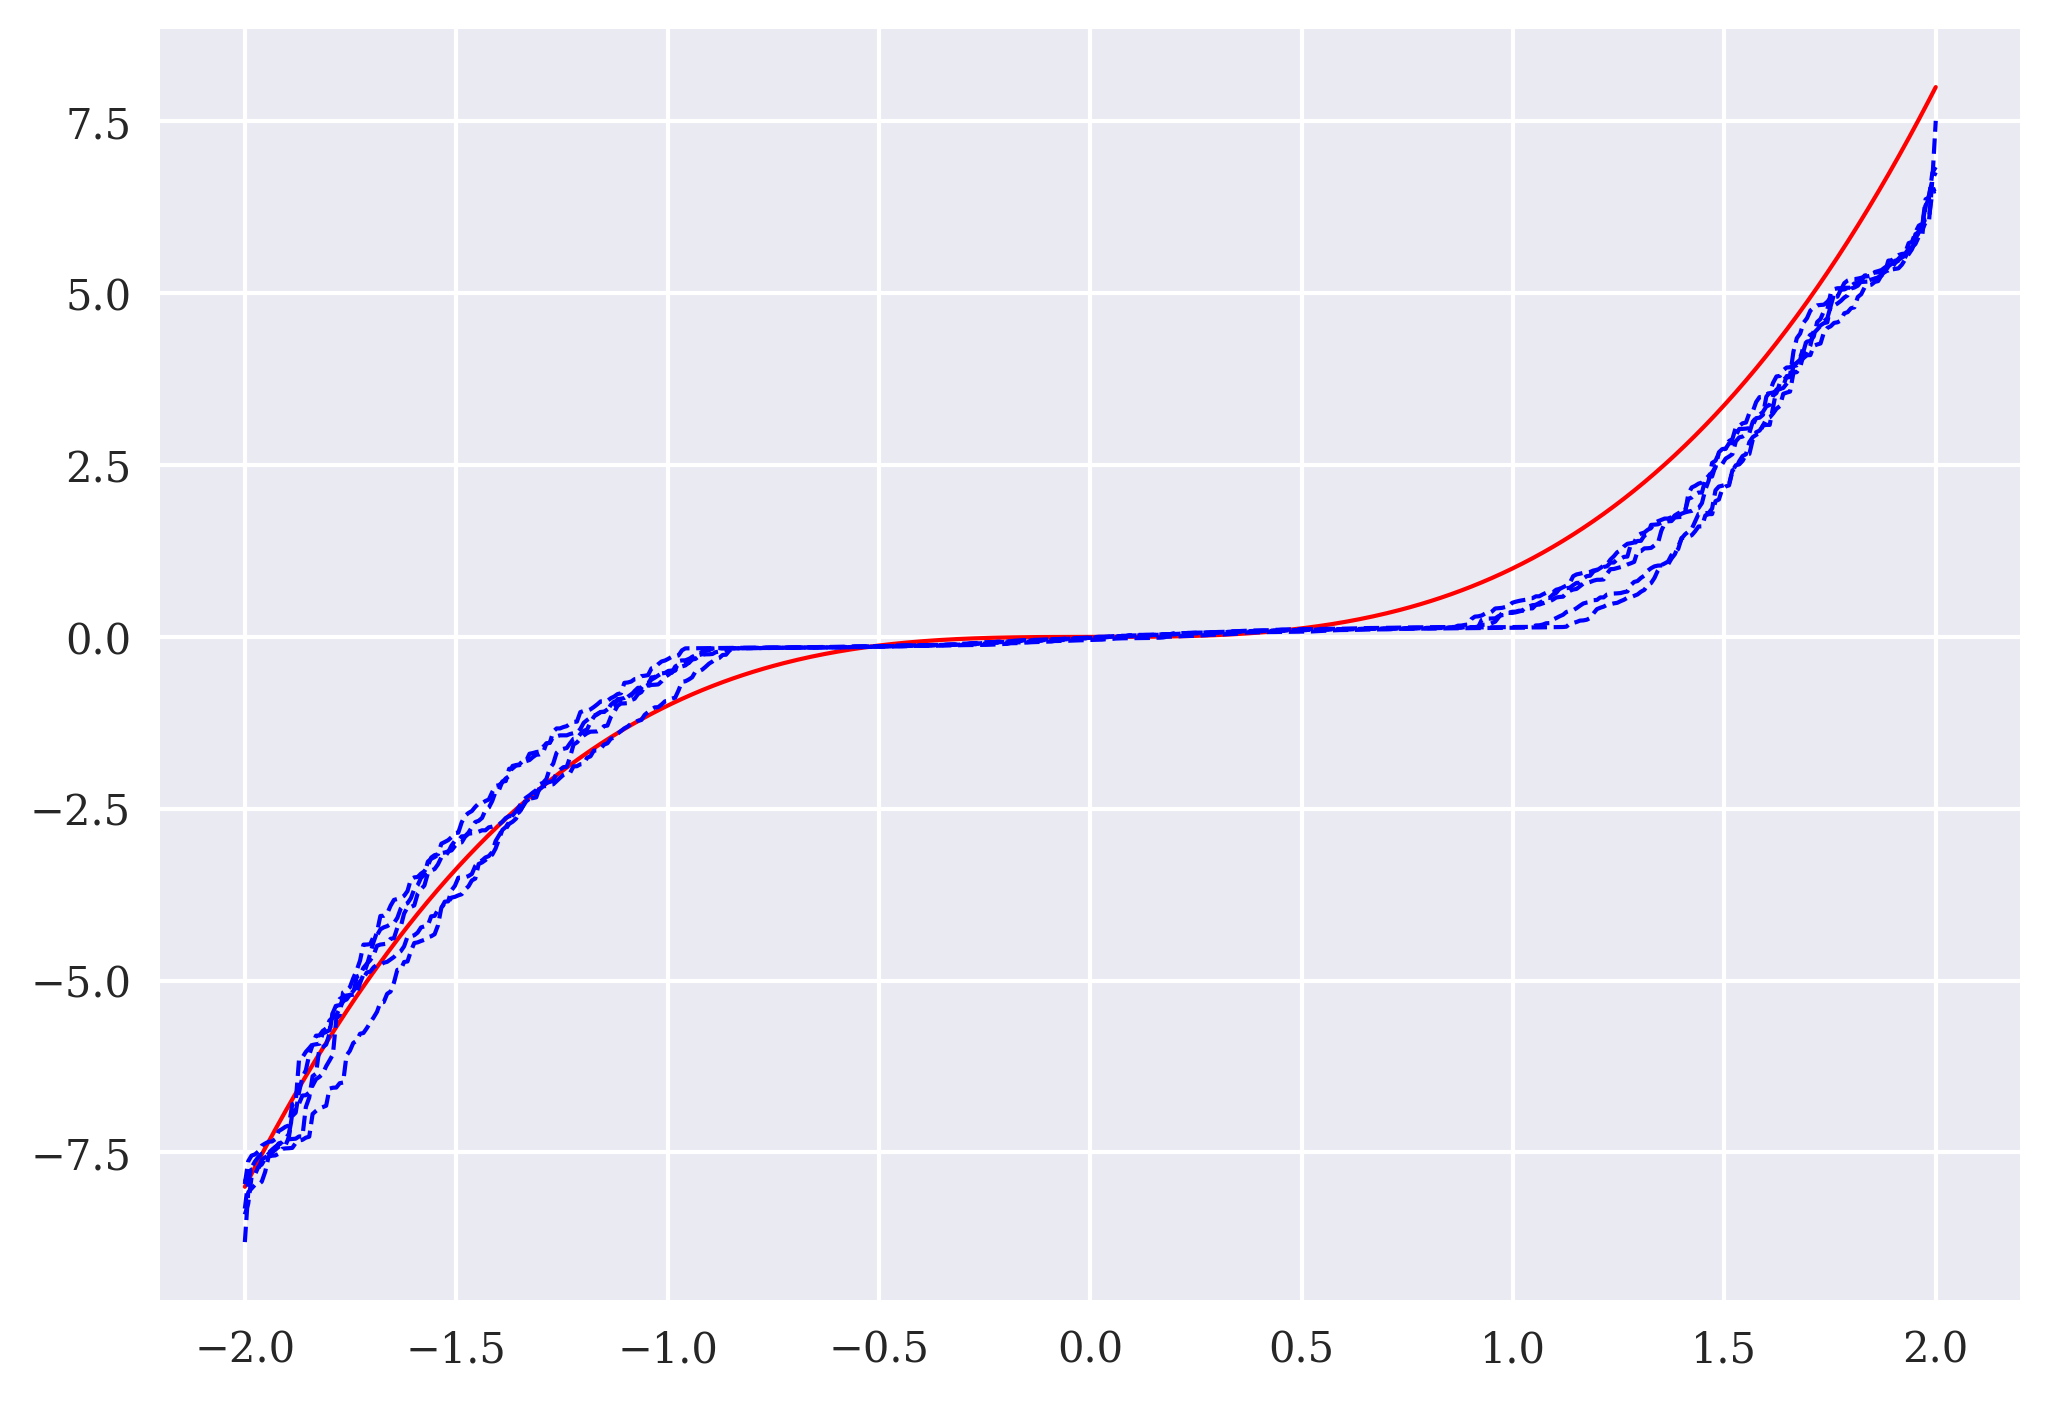

In [21]:
data.apply(np.sort).plot(
    style=['r'] + N * ['b--'], lw=1, legend=False);

## Financial Example — GLD Log-Returns

In [22]:
prices = load_eod(symbol='GLD', n_obs=2 * 252)
rets = compute_log_returns(prices)

In [23]:
scaler = ReturnScaler()
rets_ = scaler.fit_transform(rets)

In [24]:
generator = Generator(latent_dim=1, hidden_units=24, output_dim=1)
discriminator = Discriminator(input_dim=1, hidden_units=24)

In [25]:
%%time
history = train_gan(
    generator, discriminator, rets_.reshape(-1, 1),
    epochs=5001, batch_size=32,
    lr_d=0.001, lr_g=0.0001, seed=100
)

Epoch     0 | D_real: 0.7045 D_fake: 0.6751 G: 0.7090
Epoch  1000 | D_real: 0.6982 D_fake: 0.7271 G: 0.7219
Epoch  2000 | D_real: 0.6865 D_fake: 0.6899 G: 0.6805
Epoch  3000 | D_real: 0.7065 D_fake: 0.6805 G: 0.7113
Epoch  4000 | D_real: 0.7057 D_fake: 0.6682 G: 0.6912
Epoch  5000 | D_real: 0.6957 D_fake: 0.6975 G: 0.6950
CPU times: user 1.99 s, sys: 5.49 ms, total: 2 s
Wall time: 2 s


### Generating Synthetic Returns

In [26]:
data = pd.DataFrame({'real': rets})
N = 25
for i in range(N):
    samples = generate_samples(generator, len(rets_), latent_dim=1)
    data[f'synth_{i:02d}'] = scaler.inverse_transform(samples)

In [27]:
describe_comparison(data, n_show=5)

,real,synth_00,synth_01,synth_02,synth_03
count,503.0000,503.0000,503.0000,503.0000,503.0000
mean,0.0014,0.0016,0.0025,0.0012,0.0002
std,0.0111,0.0097,0.0106,0.0106,0.0103
min,-0.0664,-0.0306,-0.0375,-0.0411,-0.0390
25%,-0.0044,-0.0043,-0.0036,-0.0054,-0.0051
50%,0.0018,0.0013,0.0036,0.0014,0.0003
75%,0.0082,0.0080,0.0086,0.0075,0.0065
max,0.0363,0.0281,0.0339,0.0290,0.0300


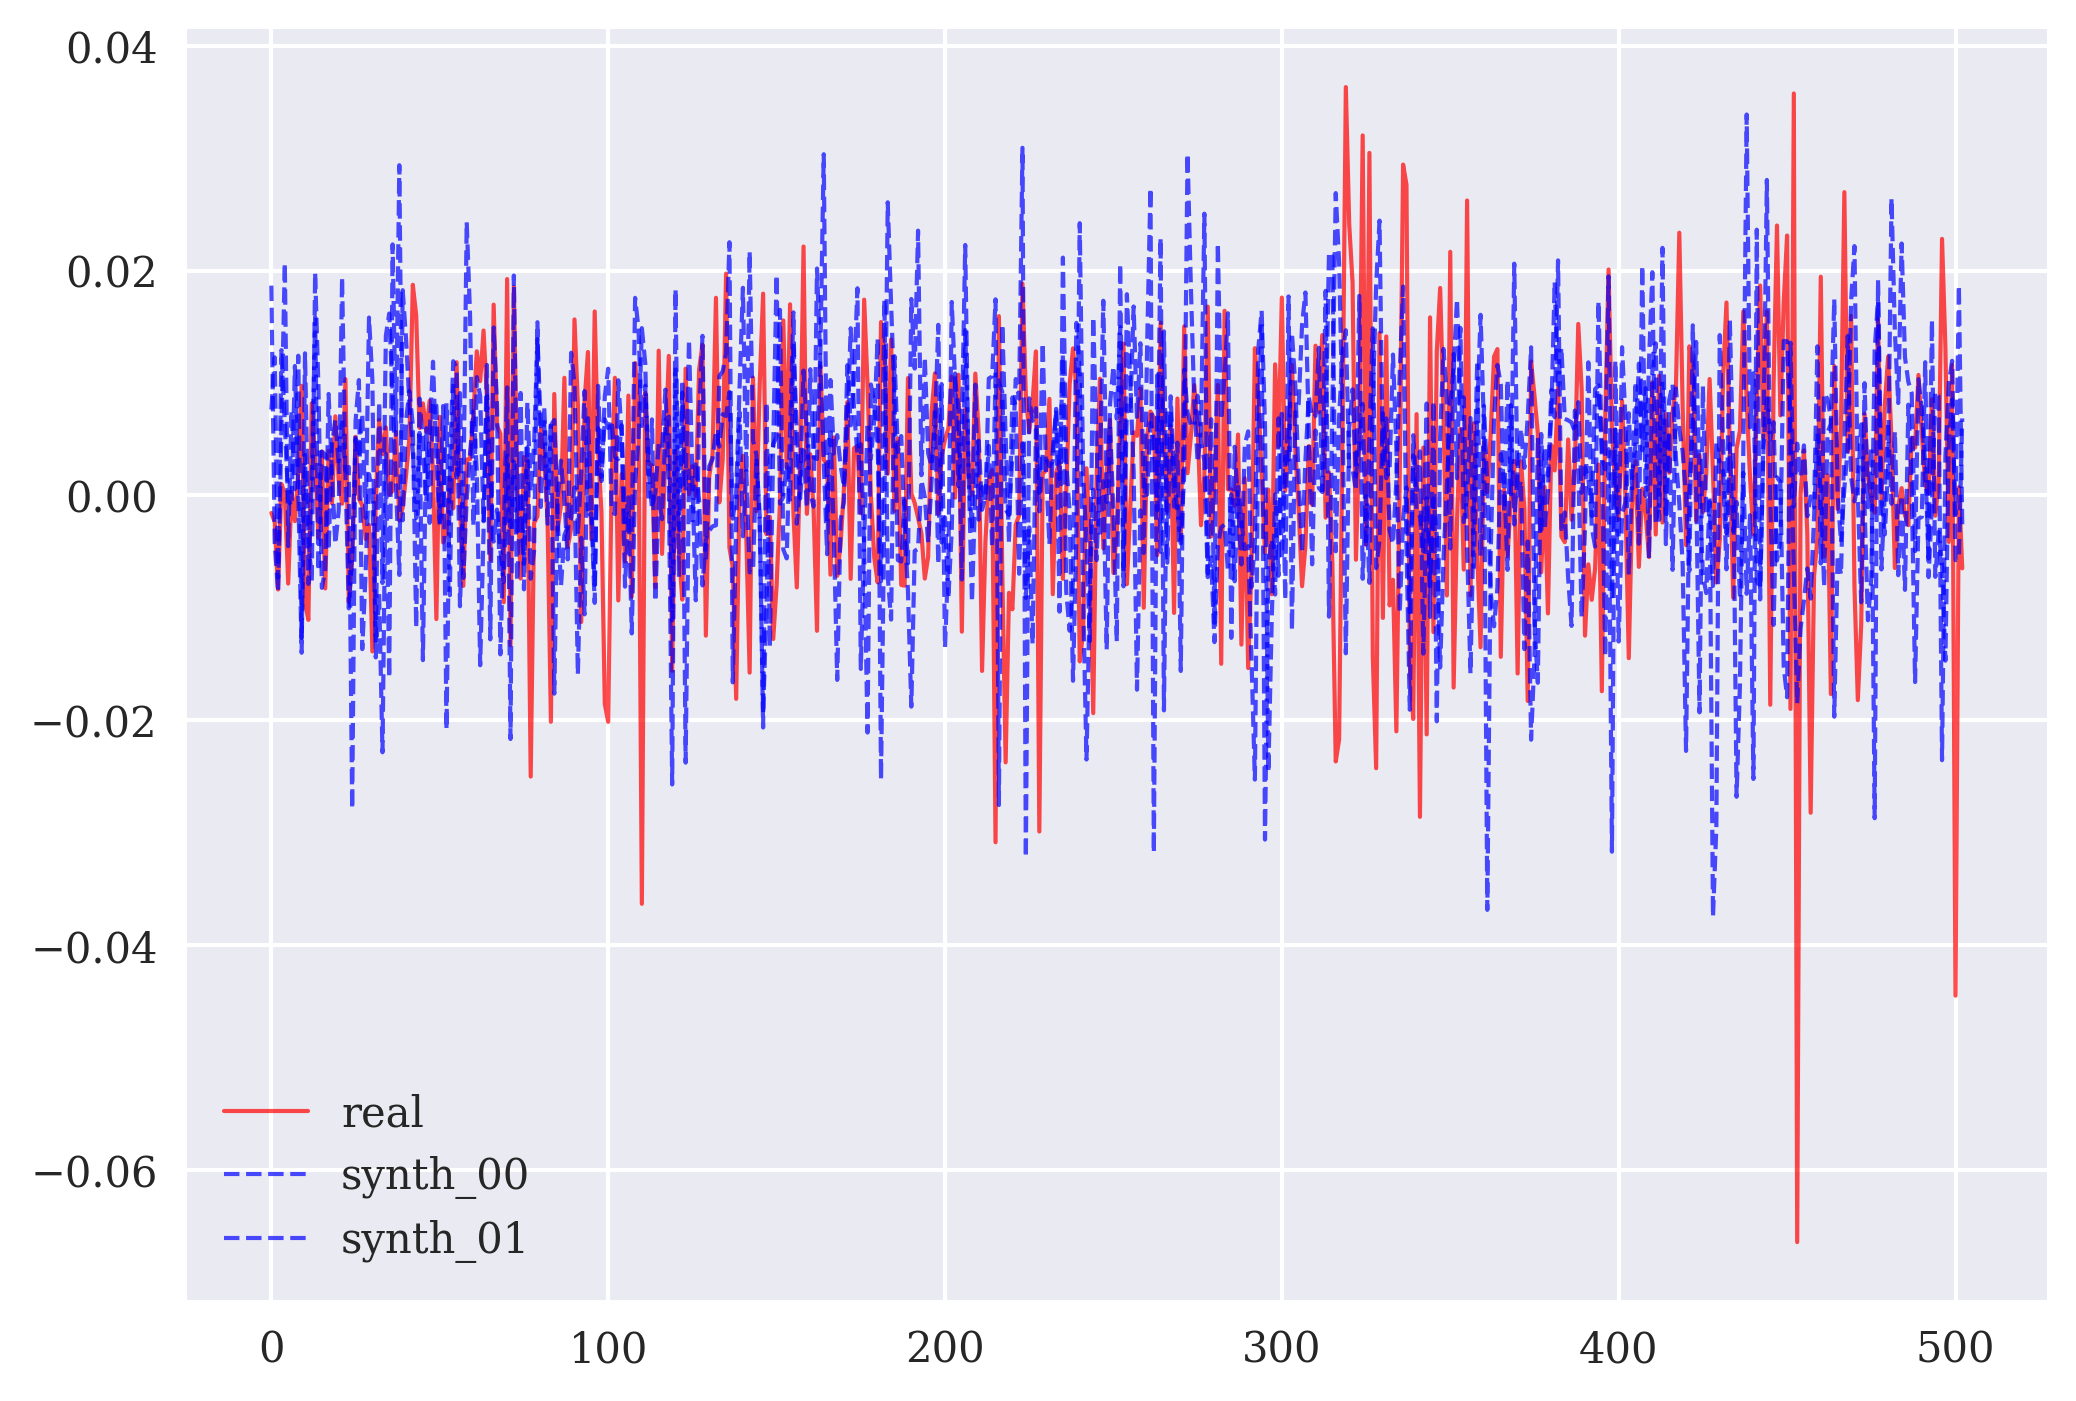

In [28]:
plot_real_vs_synth(data, n_synth=2);

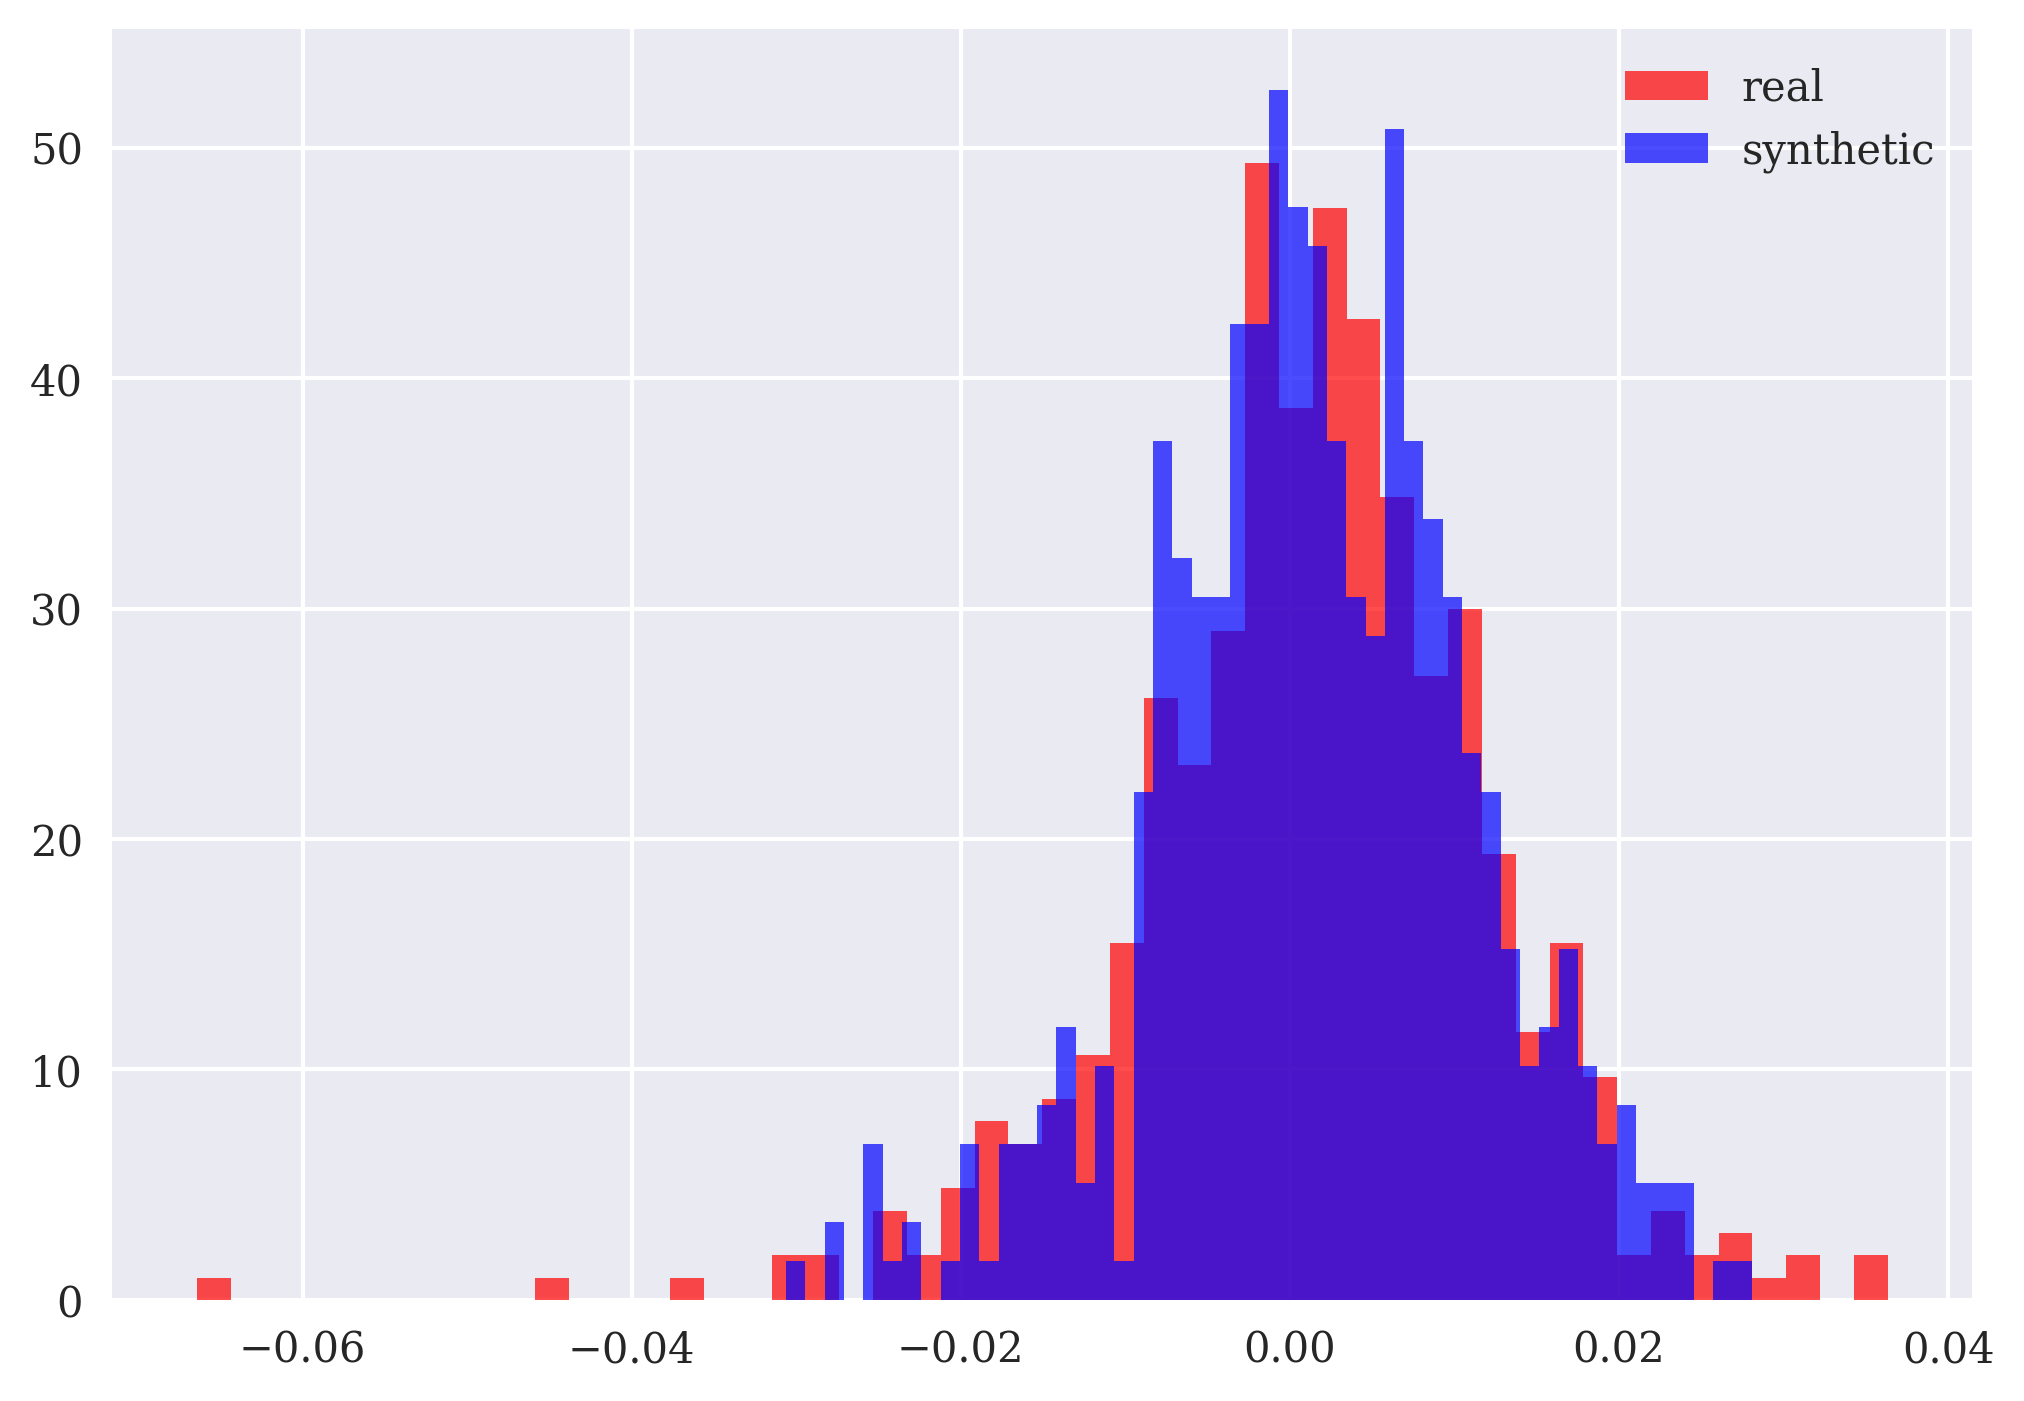

In [29]:
plot_histograms(data['real'].values, data['synth_00'].values);

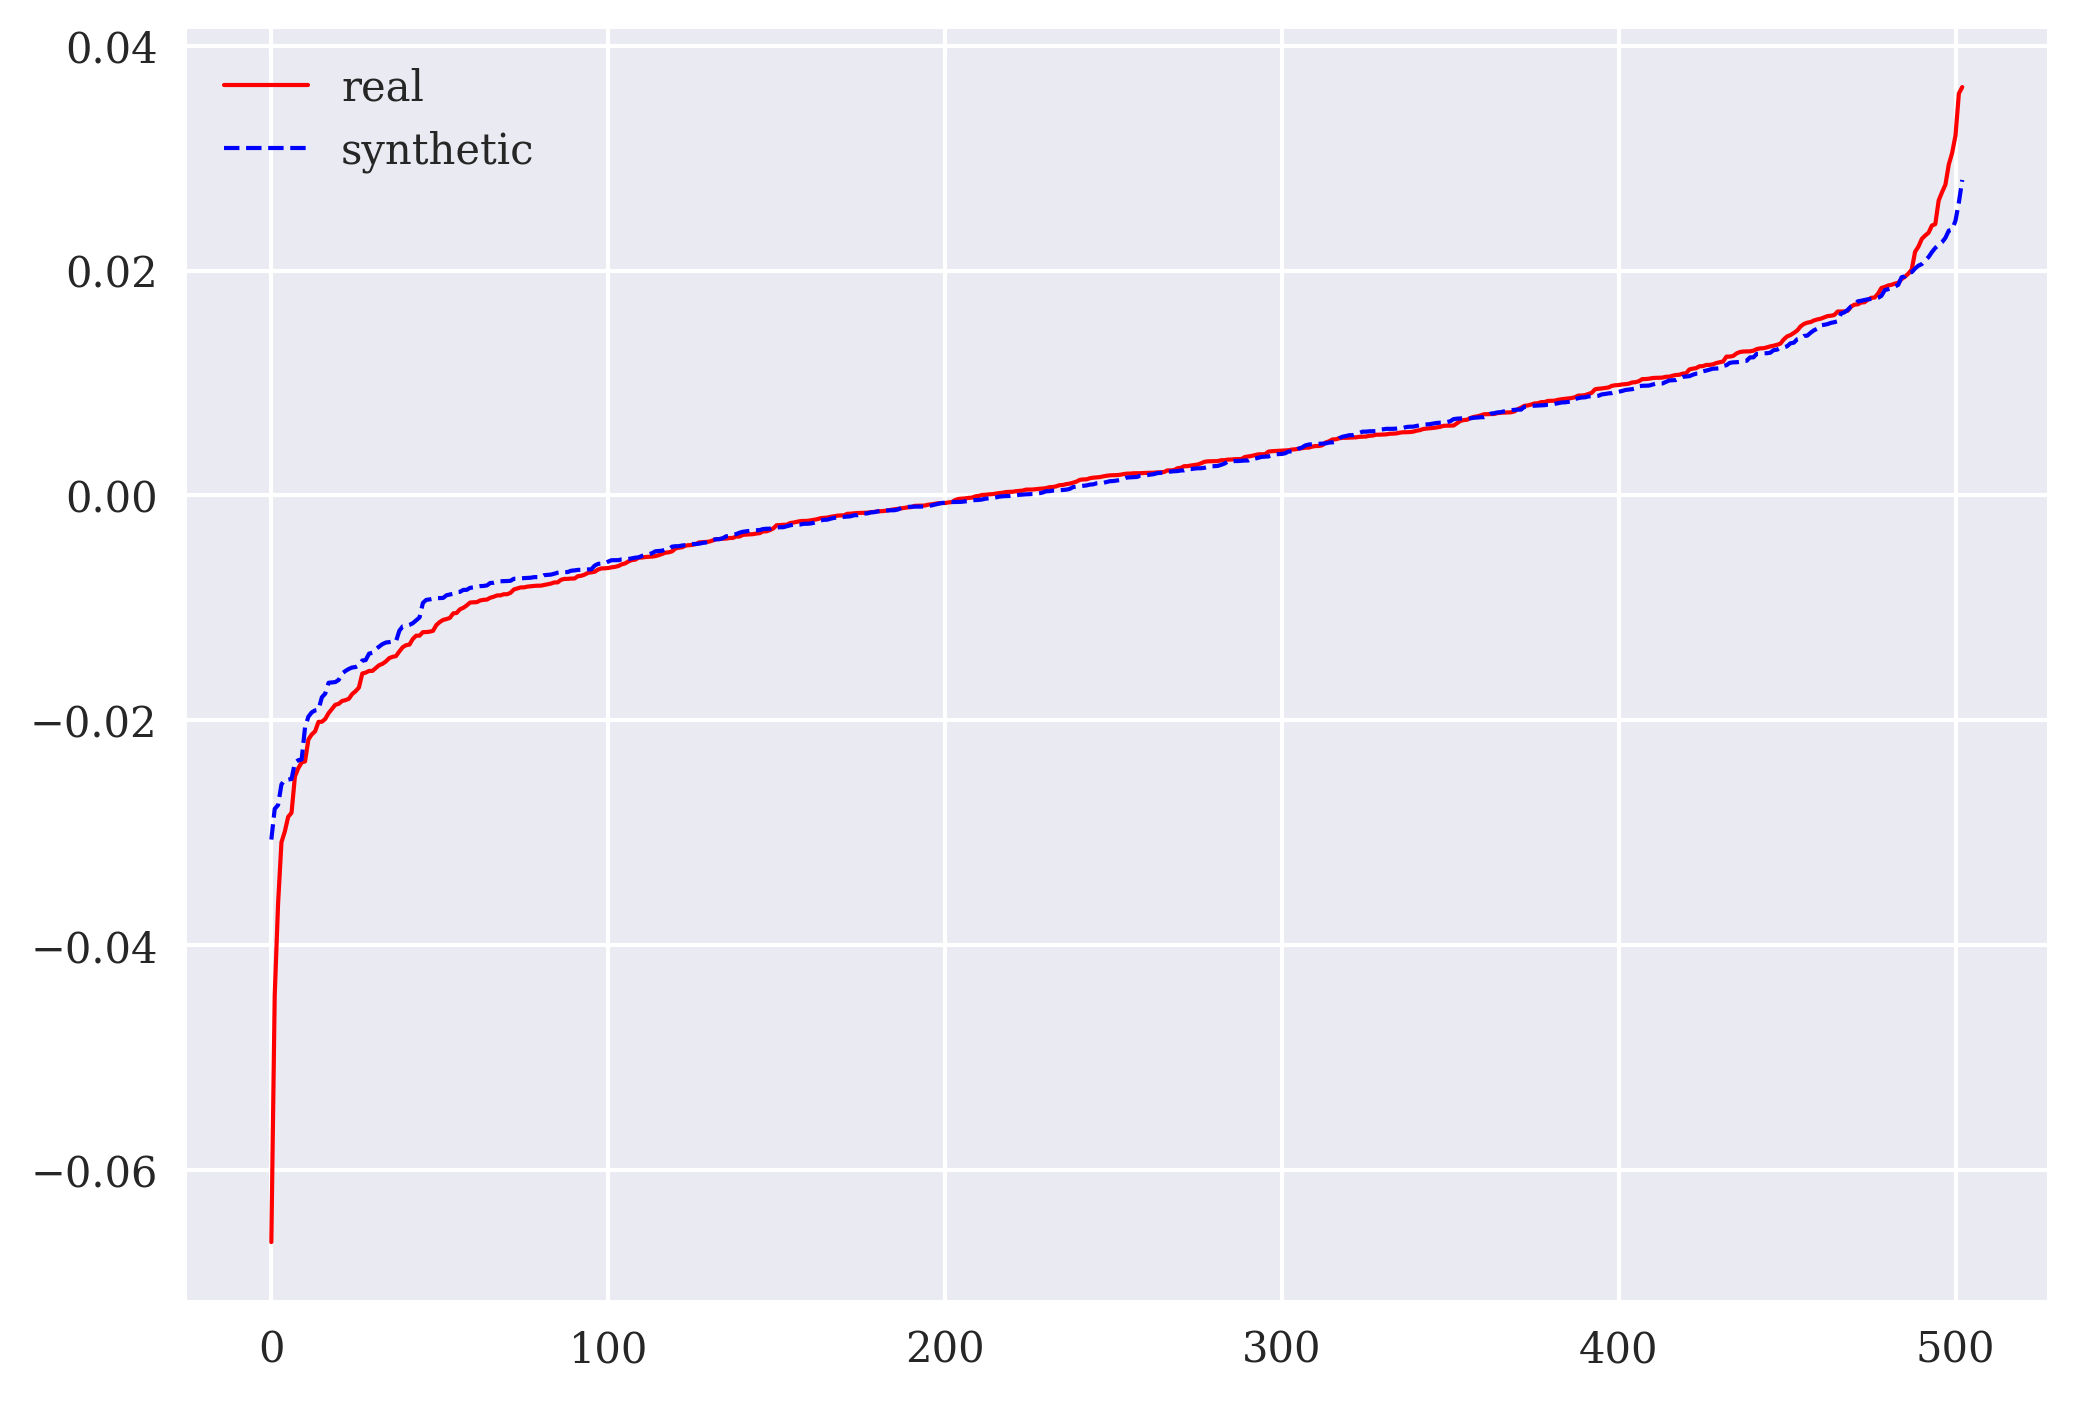

In [30]:
plot_sorted(data['real'].values, data['synth_00'].values);

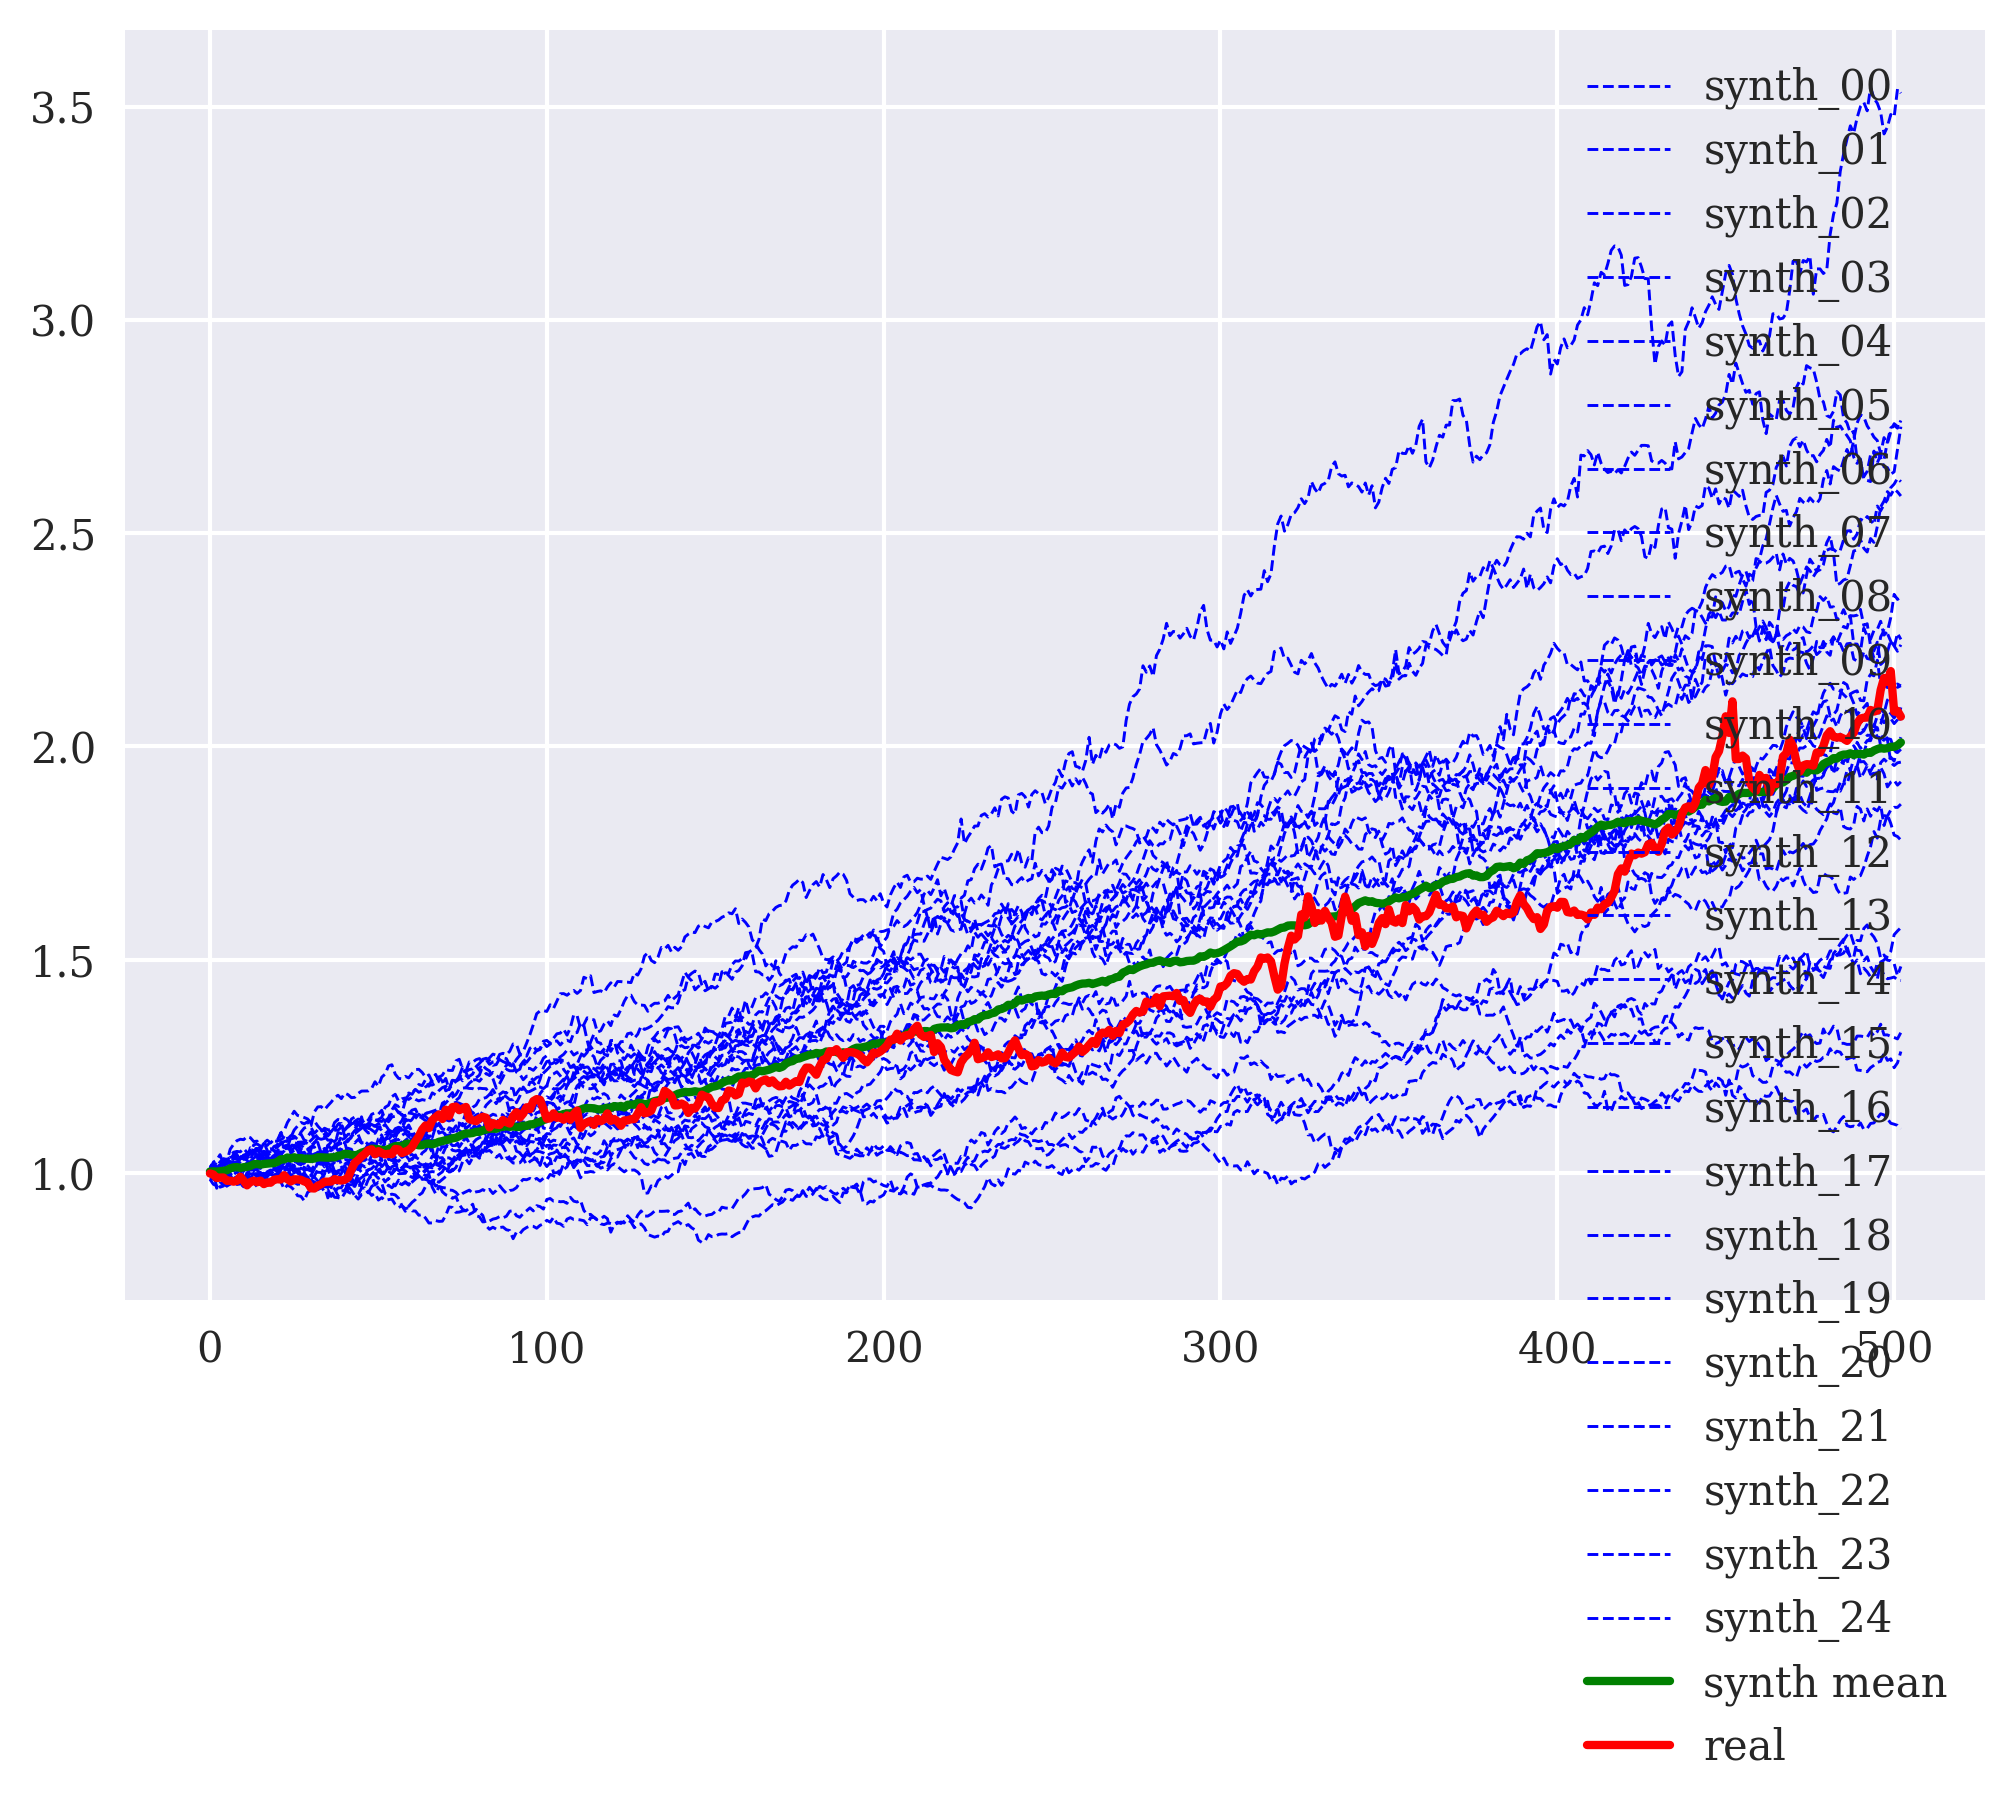

In [31]:
plot_cumulative(data, n_synth=N);

### Kolmogorov-Smirnov Test

In [ ]:
synth_cols = [c for c in data.columns if c.startswith('synth')]
pvals = ks_test_batch(data['real'].values, data[synth_cols])
pvals.round(4)

In [ ]:
f'KS pass rate: {pass_rate(pvals):.0%}'

In [ ]:
plot_pvalue_histogram(pvals);

<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>